# Módulo 1: Pipeline y Tratamiento de Datos Topográficos Planetarios (DEM)
### Marswalk 3D — NASA Space Apps Challenge

---

## 1. Contexto de Misión y Altimetría Marciana
En la exploración de la superficie de Marte, la selección de trayectorias transitables depende críticamente de **Modelos Digitales de Elevación (DEM)** derivados de sensores orbitales de la NASA:
- **MOLA (Mars Orbiter Laser Altimeter):** Misión *Mars Global Surveyor* (altimetría láser global, referencia geodésica).
- **CTX (Context Camera) & HiRISE:** Misión *Mars Reconnaissance Orbiter* (fotogrametría estereoscópica de alta resolución, 0.25 a 20 m/px).

En este módulo implementamos el pipeline completo de ingeniería de datos para procesar altimetría Float32 sin pérdida de precisión, realizar consultas continuas $O(1)$ mediante interpolación bilineal y computar el operador de gradiente para pendiente topográfica real.


In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Detectar y agregar la raíz del repositorio al path de forma dinámica
for candidate in [Path("."), Path(".."), Path("Optimal_Route"), Path("../Optimal_Route")]:
    resolved = candidate.resolve()
    if (resolved / "src" / "dem_pipeline.py").is_file():
        repo_root = resolved
        break
else:
    repo_root = Path("..").resolve()

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.dem_pipeline import DEMPipeline

# Cargar dataset de prueba (Cráter Jezero)
data_dir = repo_root / "data" / "jezero_test"
dem_pipe = DEMPipeline(data_dir)

print(f"Dataset cargado: {dem_pipe.metadata['label']}")
print(f"Dimensiones de la matriz: {dem_pipe.rows} filas × {dem_pipe.cols} columnas")
print(f"Extensión espacial métrica: {dem_pipe.width_m:.1f} m (Este-Oeste) × {dem_pipe.depth_m:.1f} m (Norte-Sur)")
print(f"Resolución espacial nativa: {dem_pipe.resolution_m} m/píxel")
print(f"Rango de elevación geodésica: [{dem_pipe.min_elev_m:.2f}, {dem_pipe.max_elev_m:.2f}] metros")


Dataset cargado: Jezero (dataset de prueba)
Dimensiones de la matriz: 1512 filas × 1596 columnas
Extensión espacial métrica: 31920.0 m (Este-Oeste) × 30240.0 m (Norte-Sur)
Resolución espacial nativa: 20.0 m/píxel
Rango de elevación geodésica: [-2710.70, -1515.54] metros


## 2. Muestreo Continuo: Interpolación Bilineal $O(1)$

En una simulación 3D interactiva o un optimizador de rutas continuo, un agente puede situarse en cualquier coordenada métrica real $(x_m, z_m)$ que no coincide exactamente con los centros de los píxeles discretos del DEM.

En lugar de recurrir a operaciones costosas de raycasting poligonal ($O(\text{triángulos})$), implementamos un muestreo analítico bilineal $O(1)$:

Dada una coordenada continua normalizada en la celda $(f_c, f_r) \in [0, 1] \times [0, 1]$ rodeada por los 4 vértices del píxel:
$$z(f_c, f_r) = (1 - f_c)(1 - f_r) h_{00} + f_c (1 - f_r) h_{10} + (1 - f_c) f_r h_{01} + f_c f_r h_{11}$$


In [2]:
# Demostración del muestreo continuo O(1)
test_points = [
    (0.0, 0.0),          # Centro del mapa
    (-4000.0, 2500.0),   # Región interior del cráter
    (5234.7, -3141.2),   # Coordenada submétrica arbitraria
]

print("--- Consultas de Elevación en Tiempo Constante O(1) ---")
for x, z in test_points:
    elev = dem_pipe.sample_elevation_m(x, z)
    elev_rel = dem_pipe.sample_relative_elevation_m(x, z)
    print(f"Punto ({x:+8.1f} m, {z:+8.1f} m) -> Elevación Absoluta: {elev:8.2f} m | Relativa: {elev_rel:8.2f} m")


--- Consultas de Elevación en Tiempo Constante O(1) ---
Punto (    +0.0 m,     +0.0 m) -> Elevación Absoluta: -2550.52 m | Relativa:   160.18 m
Punto ( -4000.0 m,  +2500.0 m) -> Elevación Absoluta: -2489.50 m | Relativa:   221.20 m
Punto ( +5234.7 m,  -3141.2 m) -> Elevación Absoluta: -2562.80 m | Relativa:   147.90 m


## 3. Operador de Gradiente Discreto y Pendiente Real

La **pendiente topográfica ($\theta$)** es el parámetro crítico para la seguridad del astronauta y el consumo de oxígeno.

A diferencia de motores gráficos que calculan la normal de la malla distorsionada por la exageración vertical visual, aquí calculamos la pendiente real sobre el DEM en metros utilizando **diferencias finitas centrales**:

$$\nabla z = \left( \frac{\partial z}{\partial x}, \frac{\partial z}{\partial z} \right) \approx \left( \frac{z(x + \Delta x, z) - z(x - \Delta x, z)}{2 \Delta x}, \frac{z(x, z + \Delta z) - z(x, z - \Delta z)}{2 \Delta z} \right)$$

$$\|\nabla z\| = \sqrt{\left(\frac{\partial z}{\partial x}\right)^2 + \left(\frac{\partial z}{\partial z}\right)^2}$$

$$\theta = \arctan(\|\nabla z\|) \quad \text{[radianes]} \Longrightarrow \theta^\circ = \theta \times \frac{180^\circ}{\pi}$$


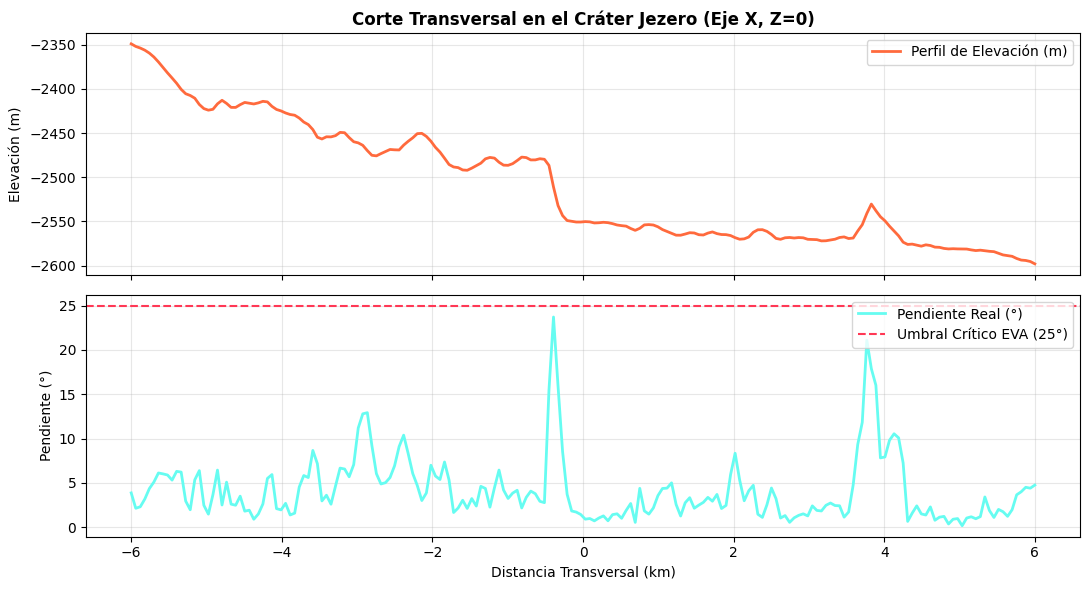

In [3]:
# Cálculo de pendiente sobre un perfil transversal
x_profile = np.linspace(-6000, 6000, 200)
z_fixed = 0.0

elevations = [dem_pipe.sample_elevation_m(x, z_fixed) for x in x_profile]
slopes = [dem_pipe.sample_slope_deg(x, z_fixed) for x in x_profile]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax1.plot(x_profile / 1000, elevations, color="#ff6a3d", lw=2, label="Perfil de Elevación (m)")
ax1.set_ylabel("Elevación (m)")
ax1.set_title("Corte Transversal en el Cráter Jezero (Eje X, Z=0)", fontsize=12, fontweight="bold")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper right")

ax2.plot(x_profile / 1000, slopes, color="#66fcf1", lw=2, label="Pendiente Real (°)")
ax2.axhline(25.0, color="#ff3855", ls="--", lw=1.5, label="Umbral Crítico EVA (25°)")
ax2.set_xlabel("Distancia Transversal (km)")
ax2.set_ylabel("Pendiente (°)")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


## 4. Mapa Topográfico 2D y Mapa de Pendientes de Jezero


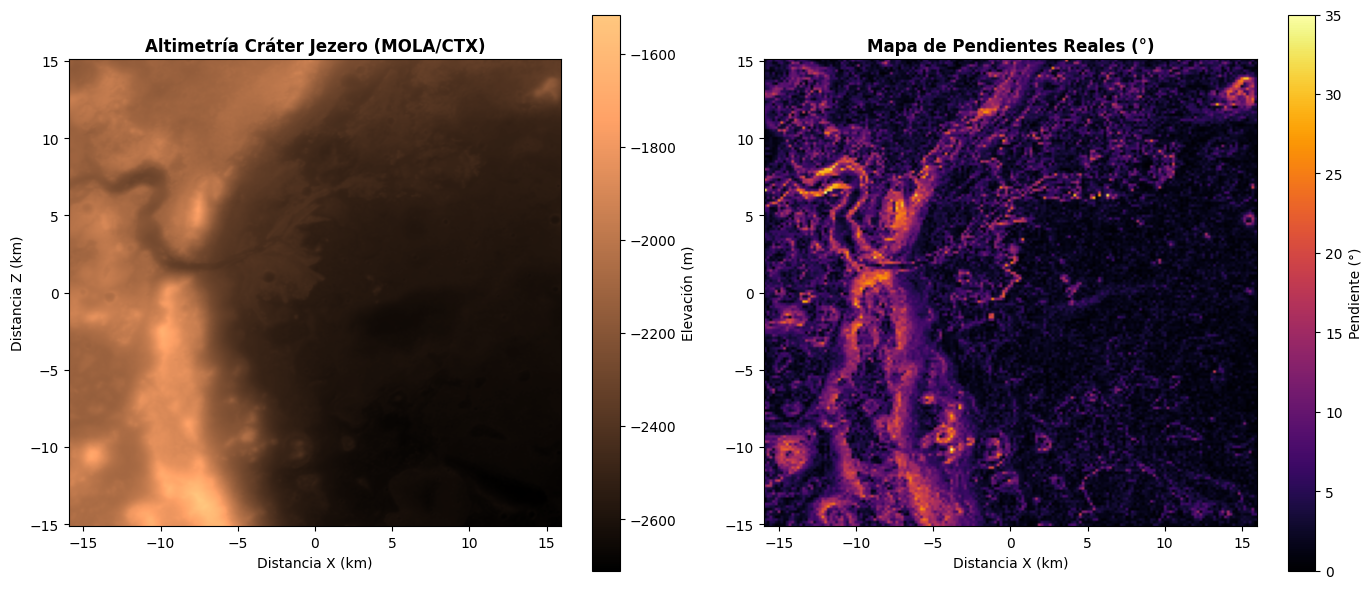

In [4]:
# Generar mapa bidimensional de pendientes para análisis de navegabilidad
slope_map = dem_pipe.compute_slope_map(target_rows=180, target_cols=180)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

im1 = ax1.imshow(dem_pipe.dem, cmap="copper", extent=[-dem_pipe.half_w/1000, dem_pipe.half_w/1000, -dem_pipe.half_d/1000, dem_pipe.half_d/1000])
ax1.set_title("Altimetría Cráter Jezero (MOLA/CTX)", fontweight="bold")
ax1.set_xlabel("Distancia X (km)")
ax1.set_ylabel("Distancia Z (km)")
fig.colorbar(im1, ax=ax1, label="Elevación (m)")

im2 = ax2.imshow(slope_map, cmap="inferno", extent=[-dem_pipe.half_w/1000, dem_pipe.half_w/1000, -dem_pipe.half_d/1000, dem_pipe.half_d/1000], vmin=0, vmax=35)
ax2.set_title("Mapa de Pendientes Reales (°)", fontweight="bold")
ax2.set_xlabel("Distancia X (km)")
fig.colorbar(im2, ax=ax2, label="Pendiente (°)")

plt.tight_layout()
plt.show()
